# Demo of diffusion-based FWI on Marmousi model (step2)

## Description
This notebook implements DMFWI using Deepwave and PyTorch.  
It is designed for generating synthetic seismic data, performing wave propagation simulation, and updating velocity models through gradient-based optimization.

## Workflow
1. Import required libraries
2. Load velocity model and acquisition parameters
3. Generate source wavelets and geometry
4. Run forward simulation
5. Compute loss between observed and simulated data
6. Update model parameters
7. Visualize results

## Author
Chao Li

## Date
2026-04-07

In [1]:
import time
import torch
from torchvision import transforms as T, utils
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import io
import hydra
from omegaconf import DictConfig
import os
import sys
import deepwave
from deepwave import scalar
from torch.optim import Adam
from torchaudio.functional import biquad
from scipy.ndimage import gaussian_filter
from scipy.signal import butter
from torch import optim
import sys
from utils.utils import *
from diffusionreg import myprediff
from denoising_diffusion_pytorch.denoising_diffusion_pytorch_only import num_to_groups, Trainer, Unet, GaussianDiffusion
from hydra import initialize, compose
from omegaconf import DictConfig

/home/lcgeo/anaconda3/envs/lcgeopy/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dx        = 25                 # step interval along x/z direction
dt        = 0.003                # time interval (e.g., 3ms)
num_dims  = 2                     # dimension of velocity model
nz        = 141                  # model shape of z dimension (depth) Marmousi2
ny        = 681                   # model shape of y dimension Marmousi2
vmodel_dim = np.array([nz, ny])

total_t   = 6                      # totle sampling time (unit: s)
nt        = int(total_t / dt)       # number of time sampling points
num_shots = 65                  # nunmber of shots
num_sources_per_shot = 1            # number of sources per shot
num_receivers_per_shot = 680        # number of receivers per shot


source_spacing=10 ###this is the number of grid not the real distance 6:dx*6=150m
receiver_spacing=1 ###this is the number of grid not the real distance 1=25m

source_depth = 0                # the index depth of sources, default is 0
receiver_depth = 0              # the index depths of receivers, default is 0
order          = 8              # precision order of finite difference in space domain

fwi_lr            = 2       # learning rate for updating the model.
fwi_batch         = 65      # number of batches for FWI.
fwi_num_epochs    = 20       # number of FWI iteration test
survey_pad = None
savepoch = 50                 # Saving models each 50 FWI iterations
first_source=0
n_sources_per_shot=1
first_receiver=0

diffreg=1                     ####whther use diffusion regularization
nwater=19                     #### thickness of water layer

Text(0.5, 1.0, 'Initial')

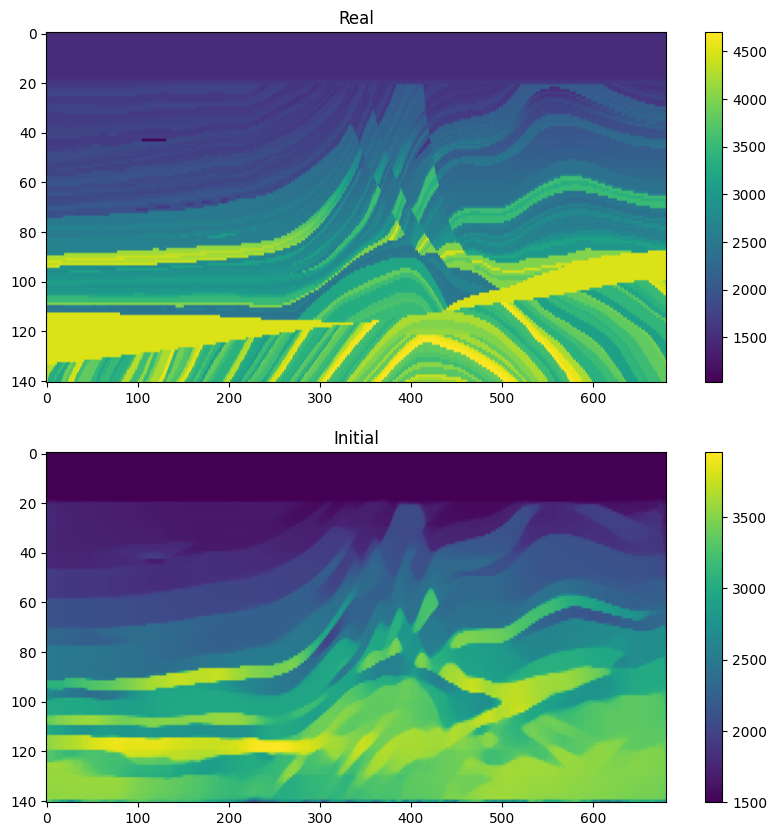

In [ ]:
torch.backends.cudnn.enabled = True     ######activate CUDNN
torch.backends.cudnn.benchmark = True   ######select the optimal optimization method

cuda_available = torch.cuda.is_available()
device = torch.device("cuda:0" if cuda_available else "cpu")

directadd=os.path.join(os.getcwd())


data_path = directadd+'/data_marmall/vel_marm_281_1361.bin'
initsafile = directadd+'/data_marmall/mar_big_initsource.mat'
initfile = directadd+'/results/Marmnpy/dfwimarm_step1.npy'

fwi_resultnpy = directadd+'/results/Marmnpy/'


# Loading the true model
model_true = loadtruemodel(data_path, num_dims, vmodel_dim).to(device)

model= np.load(initfile)
model[0:nwater,:]=1500

model_init = model

model = torch.tensor(model_init).float().to(device) 

model.requires_grad = True 
model = torch.nn.Parameter(model)

plt.figure(figsize=(10,10))
plt.subplot(2,1,1)
plt.imshow(model_true.detach().cpu().numpy(),aspect='auto')
plt.colorbar()
plt.title("Real")
plt.subplot(2,1,2)
plt.imshow(model.detach().cpu().numpy(),aspect='auto')
plt.colorbar()
plt.title("Initial")



Text(0.5, 1.0, 'Observed shots')

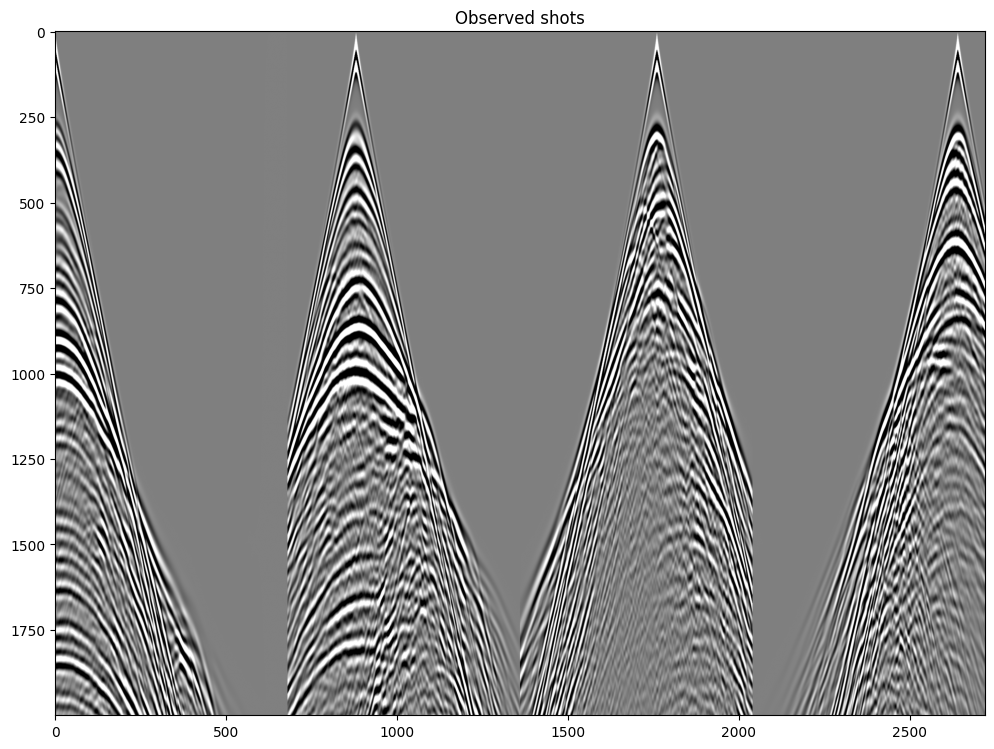

In [4]:
# Creating source and reciver locations

source_locations = torch.zeros(
            num_shots, n_sources_per_shot, 2, dtype=torch.long, device=device
        )
source_locations[..., 1] = source_depth

source_locations[:, 0, 0] = torch.arange(num_shots) * source_spacing + first_source



receiver_locations = torch.zeros(
            num_shots, num_receivers_per_shot, 2, dtype=torch.long, device=device
        )
receiver_locations[..., 1] = receiver_depth
receiver_locations[:, :, 0] = (
            (torch.arange(num_receivers_per_shot) * receiver_spacing + first_receiver).repeat(num_shots, 1)
        )

source_amplitudes_init, source_amplitudes_true = loadinitsource(initsafile,device)
source = source_amplitudes_init.repeat(1,num_shots, num_sources_per_shot).permute(1,0,2).permute(0,2,1)


out = deepwave.scalar(model_true.T, dx, dt, source_amplitudes=source,
             source_locations=source_locations,
             receiver_locations=receiver_locations,
             accuracy=8,         
             pml_width=[10,10,0,10])

rcv_amps_true = out[-1].permute(2,0,1)

plt.figure(figsize=(12,10))
plt.imshow(rcv_amps_true[:,::20,:].detach().cpu().numpy().reshape(rcv_amps_true[:,::20,:].shape[0],rcv_amps_true[:,::20,:].shape[1]*rcv_amps_true[:,::20,:].shape[2]),cmap='gray',vmin=-1,vmax=1)
plt.title('Observed shots')

In [5]:
############function for diffusion regularization
def myreg(tmodel,ws1,ws2,tartime):
    with initialize(config_path="config",version_base=None):
         cfg = compose(config_name="config")
         
    modelr = myprediff(cfg, tmodel,ws1,ws2,tartime)
   
    return modelr


from torchsummary import summary

### optimizer for the velocity model
optimizer = optim.Adam([{'params': model, 'lr':fwi_lr, 'betas':(0.5, 0.9), 'eps':1e-8, 'weight_decay':0}])  #####The model here is initial model

SNR = 0.0
SSIM = 0.0
Loss = 0.0
ERROR = 0.0

#######################step 6

import torch.nn.functional as F

t_start = time.time()

# number of shots per batch
num_shots_per_batch = int(num_shots / fwi_batch)  #####30/30

for i in range(fwi_num_epochs):
    # initialization of the loss
    epoch_loss = 0.0

    for it in range(fwi_batch):
    
        iteration = i*fwi_batch+it+1
        # Set both optimizers to zero grad.
        optimizer.zero_grad()
     
        batch_src_amps = source_amplitudes_init.repeat(1, num_shots_per_batch, 1).permute(1,0,2).permute(0,2,1)

        batch_rcv_amps_true = rcv_amps_true[:,it::fwi_batch].to(device)
        

        
        batch_x_s = source_locations[it::fwi_batch].to(device)
        batch_x_r = receiver_locations[it::fwi_batch].to(device)

        

        outpre = deepwave.scalar(model.T, dx, dt, source_amplitudes=batch_src_amps,
             source_locations=batch_x_s,
             receiver_locations=batch_x_r,
             accuracy=8,         
             pml_width=[10,10,0,10])

        batch_rcv_amps_pred = outpre[-1].permute(2,0,1)
            
        d_real = (batch_rcv_amps_true).permute(1,0,2)
  
        
        
        d_real = d_real.unsqueeze(1)
        
              
              
        d_fake = (batch_rcv_amps_pred).permute(1,0,2)
    
        d_fake = d_fake.unsqueeze(1)
        

               
        
        loss =   F.pairwise_distance(d_fake, d_real, keepdim = True).mean()  
        
      
       
        epoch_loss += loss.item()
        loss.backward()
     
        
        # Clips gradient value of model
        torch.nn.utils.clip_grad_value_(model,1e3) 
        
       

        model.grad[0:nwater,:]=0 
        # Update the velocity model
        optimizer.step()
        # clip the model value that keep the minimum value is larger than 0
    
        
        model.data=torch.clamp(model.data,min=950,max=4700)
   
    ########add diffusion regularization here
    if i==fwi_num_epochs-1 and diffreg==1:
         ws1=10
         ws2=10
         tartime=100
         model=myreg(model,ws1,ws2,100).clone()
         model.requires_grad = True 

    
    Loss = np.append(Loss, epoch_loss / fwi_batch)

    # compute the SNR and SSIM
    snr = ComputeSNR(model.detach().cpu().numpy(),  
              model_true.detach().cpu().numpy())
    SNR = np.append(SNR, snr)

    ssim = ComputeSSIM(model.detach().cpu().numpy(), \
              model_true.detach().cpu().numpy())
    SSIM = np.append(SSIM, ssim)

    rerror = ComputeRE(model.detach().cpu().numpy(), \
              model_true.detach().cpu().numpy())
    ERROR = np.append(ERROR, rerror)

    print('Epoch:', i+1, 'Loss: ', epoch_loss / fwi_batch, 'SNR:', snr, 'SSIM:', ssim.cpu().detach().cpu().numpy())

                          
                        

# Estimating the FWI time
t_end = time.time()
elapsed_time = t_end - t_start
print('Running complete in {:.0f}m  {:.0f}s' .format(elapsed_time //60 , elapsed_time % 60))


Epoch: 1 Loss:  10.120308047074538 SNR: 15.735119 SSIM: 0.40042603
Epoch: 2 Loss:  8.376323964045598 SNR: 15.734835 SSIM: 0.43417838
Epoch: 3 Loss:  7.508235990084135 SNR: 15.734022 SSIM: 0.44955105
Epoch: 4 Loss:  7.054920130509597 SNR: 15.735351 SSIM: 0.45775327
Epoch: 5 Loss:  6.786868597910955 SNR: 15.739948 SSIM: 0.46355736
Epoch: 6 Loss:  6.601303790165828 SNR: 15.747166 SSIM: 0.46822447
Epoch: 7 Loss:  6.459257712730994 SNR: 15.756234 SSIM: 0.4722124
Epoch: 8 Loss:  6.341951256531935 SNR: 15.766454 SSIM: 0.47569448
Epoch: 9 Loss:  6.239995142129751 SNR: 15.777405 SSIM: 0.47881716
Epoch: 10 Loss:  6.148449963789719 SNR: 15.788802 SSIM: 0.48164123
Epoch: 11 Loss:  6.0645597971402685 SNR: 15.800424 SSIM: 0.4842481
Epoch: 12 Loss:  5.986608131115253 SNR: 15.812101 SSIM: 0.4866706
Epoch: 13 Loss:  5.913443506681002 SNR: 15.823778 SSIM: 0.4889237
Epoch: 14 Loss:  5.844122156730065 SNR: 15.835308 SSIM: 0.49101603
Epoch: 15 Loss:  5.777810283807608 SNR: 15.846744 SSIM: 0.4929838
Epoch: 

sampling loop time step L0: 100%|██████████| 100/100 [00:00<00:00, 301.82it/s]


1


sampling loop time step L0: 100%|██████████| 100/100 [00:00<00:00, 1810.51it/s]


2


...

358


sampling loop time step L0: 100%|██████████| 100/100 [00:00<00:00, 1791.53it/s]


359


sampling loop time step L0: 100%|██████████| 100/100 [00:00<00:00, 1771.96it/s]


Epoch: 20 Loss:  5.47411784025339 SNR: 15.890733 SSIM: 0.3697006
Running complete in 1m  59s


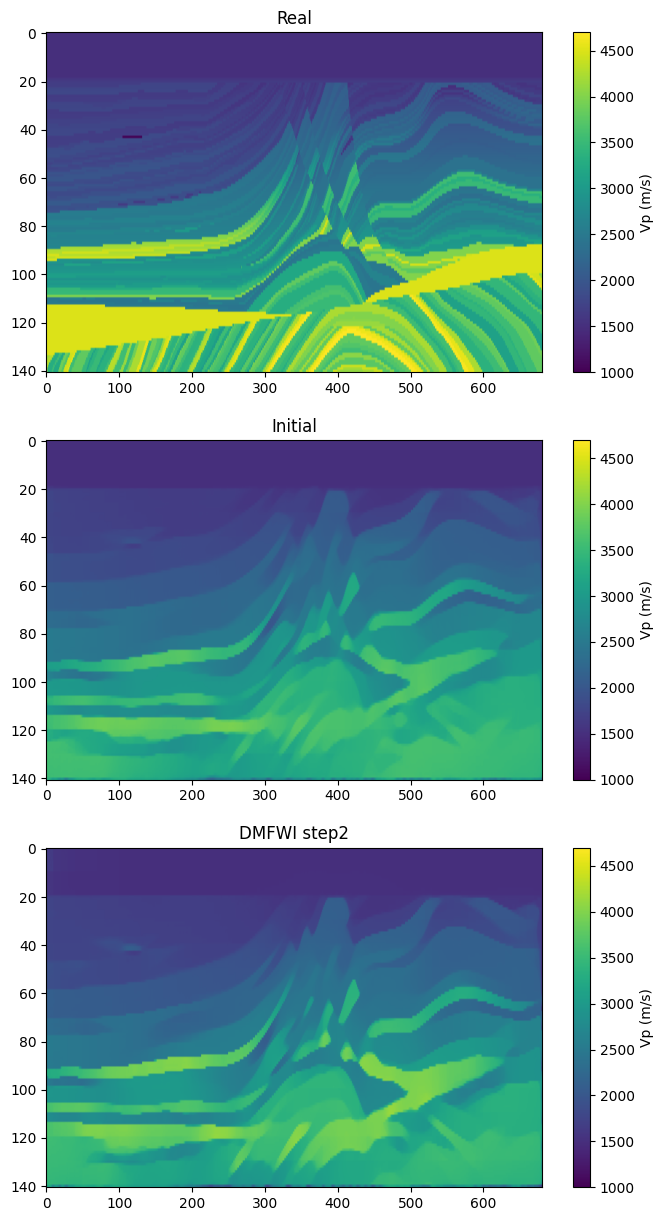

In [6]:
plt.figure(figsize=(8,15))
plt.subplot(3,1,1)
plt.imshow(model_true.detach().cpu().numpy(),aspect='auto',vmin=1000,vmax=4700)
plt.colorbar(label="Vp (m/s)")
plt.title("Real")
plt.subplot(3,1,2)
plt.imshow(model_init,aspect='auto',vmin=1000,vmax=4700)
plt.colorbar(label="Vp (m/s)")
plt.title("Initial")
plt.subplot(3,1,3)
plt.imshow(model.detach().cpu().numpy(),aspect='auto',vmin=1000,vmax=4700)
plt.colorbar(label="Vp (m/s)")
plt.title("DMFWI step2")

outnpy='dfwimarm_step2.npy'

np.save(fwi_resultnpy+ outnpy, model.cpu().data.numpy())      # save for step3